Importación de proyecto.
from google.colab import drive
drive.mount('/content/drive/MyDrive/IA_2026-2/antena_optimizer_profesional_rf_v10_colab/antenna_optimizer_professional')

Integrante del proyecto: Jeisson Estiven Cortés Antonio-2225004-Grupo F1

# Antenna Optimizer RF en Google Colab
Ejecución del motor: DEM SRTM + PSO + 3GPP + SINR + ML + mapas.


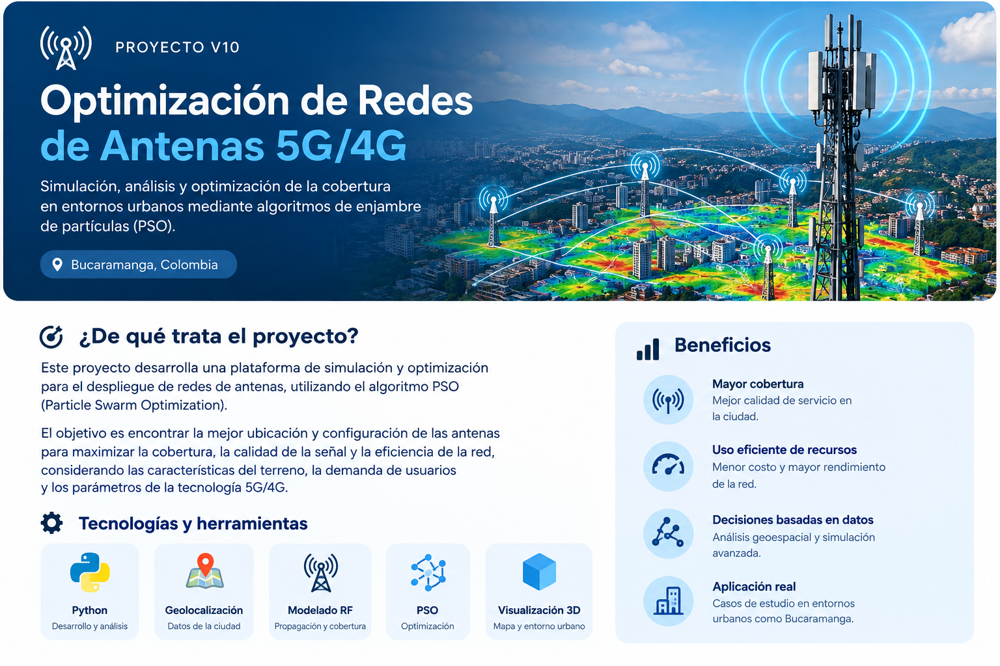

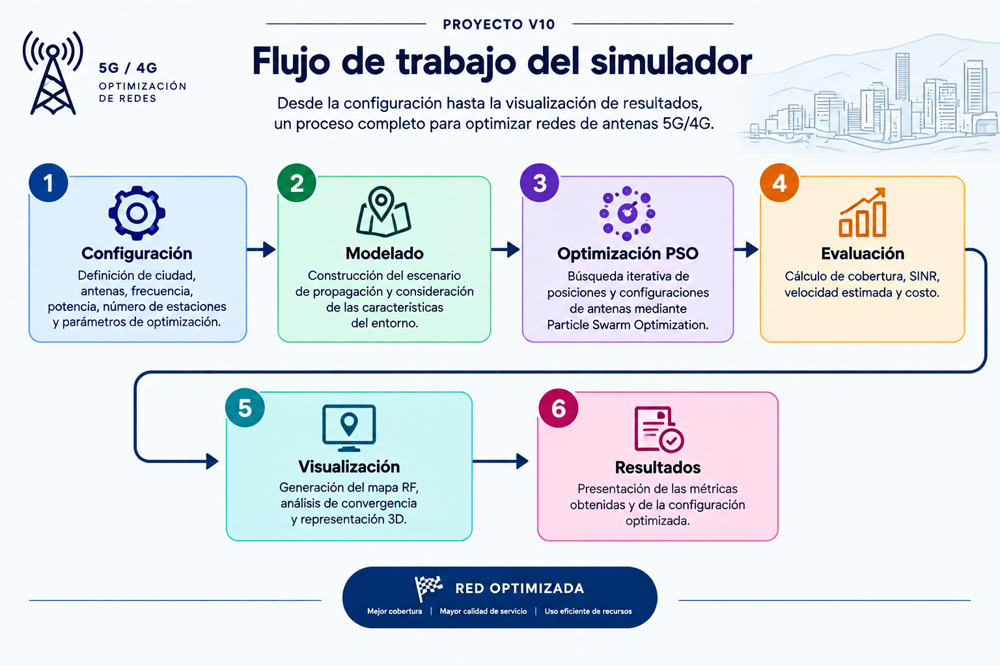

In [6]:
# @title Configuración del entorno y conexión con Google Drive
from google.colab import drive
from pathlib import Path
import sys, os

drive.mount("/content/drive")

BASE_DIR = Path(
    "/content/drive/MyDrive/IA_2026-2/"
    "antena_optimizer_profesional_rf_v10_colab/"
    "antenna_optimizer_professional"
)

OUTPUT_DIR = BASE_DIR.parent / "salidas_antenas"

sys.path.insert(0, str(BASE_DIR))
os.chdir(BASE_DIR)

!pip install -q -r requirements.txt

print("✓ Entorno listo")

Mounted at /content/drive
✓ Entorno listo


In [7]:
# @title Localización del proyecto
import os

for root, dirs, files in os.walk('/content/drive/MyDrive/IA_2026-2/antena_optimizer_profesional_rf_v10_colab/antenna_optimizer_professional'):
    if 'antenna_optimizer_professional' in root.lower():
        print("Encontrada:")
        print(root)
        break

Encontrada:
/content/drive/MyDrive/IA_2026-2/antena_optimizer_profesional_rf_v10_colab/antenna_optimizer_professional


In [8]:
# @title Verificación de archivos del proyecto
import os

print("Existe:", os.path.exists(BASE_DIR))

print("\nArchivos:")
for item in os.listdir(BASE_DIR):
    print(" -", item)

Existe: True

Archivos:
 - README.md
 - gui.py
 - antenna_catalog.py
 - FUENTES_HARDWARE.md
 - ARQUITECTURA_RF.md
 - AntennaOptimizerRF_Colab.ipynb
 - requirements.txt
 - exporters.py
 - propagation.py
 - COLAB_GUIDE.md
 - data_pipeline.py
 - ml.py
 - DEM_SOURCES.md
 - simulation.py
 - optimizer.py
 - aerial.py
 - terrain.py
 - city3d.py
 - AntennaOptimizerRF_v10_Colab.ipynb
 - services.py
 - config.py
 - COLAB_V10_README.md
 - exporters.py.bak
 - main.py
 - MEJORAS_V6.md
 - ORTOFOTO_README.txt
 - database.py
 - datos
 - __pycache__


In [9]:
# @title Instalación de dependencias del proyecto
%cd "$BASE_DIR"
!pip install -r requirements.txt -q

/content


In [10]:
# @title Verificación de librerías instaladas
import numpy
import pandas
import sklearn
import matplotlib
import plotly

print("✅ NumPy:", numpy.__version__)
print("✅ Pandas:", pandas.__version__)
print("✅ Scikit-Learn:", sklearn.__version__)
print("✅ Matplotlib:", matplotlib.__version__)
print("✅ Plotly:", plotly.__version__)


✅ NumPy: 2.4.6
✅ Pandas: 2.2.3
✅ Scikit-Learn: 1.6.1
✅ Matplotlib: 3.10.0
✅ Plotly: 5.24.1


In [11]:
# @title Configuración de la ruta de importación
import sys
sys.path.insert(0, BASE_DIR)

print("✅ Ruta del proyecto agregada:")
print(BASE_DIR)

✅ Ruta del proyecto agregada:
/content/drive/MyDrive/IA_2026-2/antena_optimizer_profesional_rf_v10_colab/antenna_optimizer_professional


In [12]:
# @title Carga de módulos del sistema
from optimizer import *
from propagation import *
from terrain import *
from city3d import *
from ml import *
from data_pipeline import *

print("✅ Todos los módulos cargaron correctamente")
from pathlib import Path

from antenna_catalog import ANTENNAS, DEFAULT_ANTENNA_KEY
from config import SimulationConfig
from services import OfflineLocationService
from simulation import run_simulation

print("✅ Motor de simulación cargado")
print("📡 Antena por defecto:", DEFAULT_ANTENNA_KEY)
print("📦 Antenas disponibles:", list(ANTENNAS.keys()))


✅ Todos los módulos cargaron correctamente
✅ Motor de simulación cargado
📡 Antena por defecto: UBIQUITI_AM-5G19-120
📦 Antenas disponibles: ['UBIQUITI_AM-5G17-90', 'UBIQUITI_AM-5G19-120', 'UBIQUITI_AM-2G16-90', 'CAMBIUM_EPMP-4X4-MU-MIMO', 'RUIJIE_RG-ANT20S-90']


In [13]:
# @title Carga del motor de simulación y catálogo de antenas
from pathlib import Path

from antenna_catalog import ANTENNAS, DEFAULT_ANTENNA_KEY
from config import SimulationConfig
from services import OfflineLocationService
from simulation import run_simulation

print("✅ Motor de simulación cargado")
print("📡 Antena por defecto:", DEFAULT_ANTENNA_KEY)
print("📦 Antenas disponibles:", list(ANTENNAS.keys()))

✅ Motor de simulación cargado
📡 Antena por defecto: UBIQUITI_AM-5G19-120
📦 Antenas disponibles: ['UBIQUITI_AM-5G17-90', 'UBIQUITI_AM-5G19-120', 'UBIQUITI_AM-2G16-90', 'CAMBIUM_EPMP-4X4-MU-MIMO', 'RUIJIE_RG-ANT20S-90']


In [14]:
# @title Configuración interactiva del escenario de simulación
# ============================================================
# CONFIGURACIÓN V10 - CELDA INTERACTIVA
# ============================================================

import ipywidgets as widgets
from IPython.display import display, clear_output

# ------------------------------------------------------------
# CAMPOS DE CONFIGURACIÓN
# ------------------------------------------------------------

city_widget = widgets.Text(
    value="Bucaramanga",
    description="Ciudad:",
    layout=widgets.Layout(width="350px")
)

antennas_widget = widgets.IntSlider(
    value=4,
    min=1,
    max=100,
    step=1,
    description="Antenas:",
    continuous_update=False,
    layout=widgets.Layout(width="400px")
)

radius_widget = widgets.FloatSlider(
    value=3,
    min=0.5,
    max=20,
    step=0.5,
    description="Radio (km):",
    continuous_update=False,
    layout=widgets.Layout(width="400px")
)

iterations_widget = widgets.IntSlider(
    value=30,
    min=5,
    max=200,
    step=5,
    description="Iteraciones:",
    continuous_update=False,
    layout=widgets.Layout(width="400px")
)

swarm_widget = widgets.IntSlider(
    value=20,
    min=5,
    max=100,
    step=5,
    description="Población:",
    continuous_update=False,
    layout=widgets.Layout(width="400px")
)

frequency_widget = widgets.IntText(
    value=5150,
    description="Frecuencia:",
    layout=widgets.Layout(width="300px")
)

power_widget = widgets.IntSlider(
    value=30,
    min=0,
    max=50,
    step=1,
    description="Potencia (dBm):",
    continuous_update=False,
    layout=widgets.Layout(width="400px")
)

bs_height_widget = widgets.FloatText(
    value=30,
    description="Altura BS (m):",
    layout=widgets.Layout(width="300px")
)

ue_height_widget = widgets.FloatText(
    value=1.5,
    description="Altura UE (m):",
    layout=widgets.Layout(width="300px")
)

bandwidth_widget = widgets.IntText(
    value=40,
    description="Ancho (MHz):",
    layout=widgets.Layout(width="300px")
)

noise_widget = widgets.FloatText(
    value=7,
    description="Noise Figure:",
    layout=widgets.Layout(width="300px")
)

sinr_widget = widgets.FloatText(
    value=3,
    description="SINR mínimo:",
    layout=widgets.Layout(width="300px")
)

spacing_widget = widgets.IntText(
    value=250,
    description="Separación (m):",
    layout=widgets.Layout(width="300px")
)

resolution_widget = widgets.IntSlider(
    value=17,
    min=5,
    max=50,
    step=1,
    description="Resolución:",
    continuous_update=False,
    layout=widgets.Layout(width="400px")
)

scenario_widget = widgets.Dropdown(
    options=["UMa", "UMi", "RMa"],
    value="UMa",
    description="Escenario:",
    layout=widgets.Layout(width="300px")
)

# Antenas disponibles
antenna_widget = widgets.Dropdown(
    options=list(ANTENNAS.keys()) if "ANTENNAS" in globals() else [DEFAULT_ANTENNA_KEY],
    value=DEFAULT_ANTENNA_KEY,
    description="Antena:",
    layout=widgets.Layout(width="400px")
)

# ------------------------------------------------------------
# BOTÓN
# ------------------------------------------------------------

apply_button = widgets.Button(
    description="⚙️ Aplicar configuración",
    button_style="success",
    icon="check",
    layout=widgets.Layout(width="250px", height="40px")
)

output = widgets.Output()

# ------------------------------------------------------------
# FUNCIÓN
# ------------------------------------------------------------

def aplicar_configuracion(b):
    global CITY
    global NUM_ANTENNAS
    global RADIUS_KM
    global ITERATIONS
    global SWARM_SIZE
    global FREQUENCY_MHZ
    global TX_POWER_DBM
    global BS_HEIGHT_M
    global UE_HEIGHT_M
    global BANDWIDTH_MHZ
    global NOISE_FIGURE_DB
    global SINR_THRESHOLD_DB
    global MIN_SPACING_M
    global DEMAND_RESOLUTION
    global SCENARIO
    global ANTENNA_KEY

    CITY = city_widget.value
    NUM_ANTENNAS = antennas_widget.value
    RADIUS_KM = radius_widget.value

    ITERATIONS = iterations_widget.value
    SWARM_SIZE = swarm_widget.value

    FREQUENCY_MHZ = frequency_widget.value
    TX_POWER_DBM = power_widget.value

    BS_HEIGHT_M = bs_height_widget.value
    UE_HEIGHT_M = ue_height_widget.value

    BANDWIDTH_MHZ = bandwidth_widget.value
    NOISE_FIGURE_DB = noise_widget.value
    SINR_THRESHOLD_DB = sinr_widget.value

    MIN_SPACING_M = spacing_widget.value
    DEMAND_RESOLUTION = resolution_widget.value

    SCENARIO = scenario_widget.value
    ANTENNA_KEY = antenna_widget.value

    with output:
        clear_output()

        print("✅ CONFIGURACIÓN APLICADA")
        print()
        print("📍 Ciudad:", CITY)
        print("📡 Antena:", ANTENNA_KEY)
        print("📶 Frecuencia:", FREQUENCY_MHZ, "MHz")
        print("⚡ Potencia:", TX_POWER_DBM, "dBm")
        print("🏗️ Escenario:", SCENARIO)
        print("📡 Número de antenas:", NUM_ANTENNAS)
        print("📏 Radio:", RADIUS_KM, "km")
        print("🔄 Iteraciones:", ITERATIONS)
        print("🐝 Población:", SWARM_SIZE)
        print()
        print("🚀 Ya puedes ejecutar las siguientes celdas.")

apply_button.on_click(aplicar_configuracion)

# ------------------------------------------------------------
# DISEÑO DE LA INTERFAZ
# ------------------------------------------------------------

titulo = widgets.HTML(
    "<h2>📡 Configuración del Simulador V10</h2>"
)

subtitulo1 = widgets.HTML("<h3>📍 Ubicación y optimización</h3>")

grupo1 = widgets.VBox([
    city_widget,
    antennas_widget,
    radius_widget,
    iterations_widget,
    swarm_widget
])

subtitulo2 = widgets.HTML("<h3>📶 Radiofrecuencia</h3>")

grupo2 = widgets.VBox([
    frequency_widget,
    power_widget,
    bandwidth_widget,
    noise_widget,
    sinr_widget
])

subtitulo3 = widgets.HTML("<h3>🏗️ Infraestructura</h3>")

grupo3 = widgets.VBox([
    bs_height_widget,
    ue_height_widget,
    spacing_widget,
    resolution_widget,
    scenario_widget,
    antenna_widget
])

display(
    widgets.VBox([
        titulo,
        subtitulo1,
        grupo1,
        subtitulo2,
        grupo2,
        subtitulo3,
        grupo3,
        widgets.HTML("<br>"),
        apply_button,
        output
    ])
)

In [16]:
# @title Verificación de parámetros de la antena seleccionada
p = ANTENNAS[ANTENNA_KEY]

print("MODELO:", p.model)
print("FABRICANTE:", p.manufacturer)
print("TIPO:", p.antenna_type)
print("BANDA:", p.frequency_min_mhz, "-", p.frequency_max_mhz, "MHz")
print("GANANCIA:", p.gain_dbi, "dBi")
print("HAZ HORIZONTAL:", p.h_beamwidth_deg, "°")
print("HAZ VERTICAL:", p.v_beamwidth_deg, "°")
print("DOWNTILT:", p.electrical_downtilt_deg, "°")
if not (p.frequency_min_mhz <= FREQUENCY_MHZ <= p.frequency_max_mhz):
    raise ValueError(
        f"La frecuencia {FREQUENCY_MHZ} MHz no está dentro "
        f"de la banda de {p.model}: "
        f"{p.frequency_min_mhz}-{p.frequency_max_mhz} MHz"
    )

print("✅ Frecuencia compatible con la antena")
cfg = SimulationConfig(
    num_antennas=NUM_ANTENNAS,
    max_distance_km=RADIUS_KM,
    iterations=ITERATIONS,
    swarm_size=SWARM_SIZE,
    frequency_mhz=FREQUENCY_MHZ,
    tx_power_dbm=TX_POWER_DBM,
    antenna_gain_dbi=p.gain_dbi,
    receiver_sensitivity_dbm=-90.0,
    min_spacing_m=MIN_SPACING_M,
    bs_height_m=BS_HEIGHT_M,
    ue_height_m=UE_HEIGHT_M,
    bandwidth_mhz=BANDWIDTH_MHZ,
    noise_figure_db=NOISE_FIGURE_DB,
    sinr_threshold_db=SINR_THRESHOLD_DB,
    demand_resolution=DEMAND_RESOLUTION,
    terrain_los_samples=7,
    load_factor=0.65,
    clutter_loss_db=2.0
)

print("✅ SimulationConfig creado")
location_service = OfflineLocationService()

loc = location_service.resolve(CITY)

print("✅ Ubicación resuelta:")
print(loc)

print("INICIANDO SIMULACIÓN V10...")
print("=" * 60)

result = run_simulation(
    loc,
    cfg,
    p,
    SCENARIO,
    None,          # DEM manual
    OUTPUT_DIR,
    None           # ortofoto/aerial
)

print("=" * 60)
print("✅ SIMULACIÓN TERMINADA")

from IPython.display import HTML, display

m = result["metrics"]

display(HTML(f"""
<div style="
display:grid;
grid-template-columns:repeat(auto-fit,minmax(170px,1fr));
gap:14px;
margin:15px 0 25px;
">

<div style="padding:20px;border-radius:12px;background:#f5f7fa;text-align:center;color:#000">
<div style="color:#000">COBERTURA</div>
<div style="font-size:28px;font-weight:bold;color:#000">{m['coverage_percent']:.1f}%</div>
</div>

<div style="padding:20px;border-radius:12px;background:#f5f7fa;text-align:center;color:#000">
<div style="color:#000">PERDIDA_DE_POTENCIA</div>
<div style="font-size:28px;font-weight:bold;color:#000">{m['mean_sinr_db']:.1f} dB</div>
</div>

<div style="padding:20px;border-radius:12px;background:#f5f7fa;text-align:center;color:#000">
<div style="color:#000">VELOCIDAD</div>
<div style="font-size:28px;font-weight:bold;color:#000">{m['mean_throughput_mbps']:.0f} Mbps</div>
</div>

<div style="padding:20px;border-radius:12px;background:#f5f7fa;text-align:center;color:#000">
<div style="color:#000">COSTO</div>
<div style="font-size:28px;font-weight:bold;color:#000">${m['cost']:,.0f}</div>
</div>

</div>
"""))

MODELO: AM-5G19-120
FABRICANTE: Ubiquiti
TIPO: Sectorial PtMP
BANDA: 5150 - 5850 MHz
GANANCIA: 18.9 dBi
HAZ HORIZONTAL: 123.0 °
HAZ VERTICAL: 4.0 °
DOWNTILT: 2.0 °
✅ Frecuencia compatible con la antena
✅ SimulationConfig creado
✅ Ubicación resuelta:
Location(name='Bucaramanga', latitude=7.1193, longitude=-73.1227, elevation_m=959.0)
INICIANDO SIMULACIÓN V10...
✅ SIMULACIÓN TERMINADA


In [17]:
# @title Preparación de la carpeta de resultados
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/IA_2026-2/"
    "antena_optimizer_profesional_rf_v10_colab/"
    "salidas_antenas"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("📁 Resultados:")
print(OUTPUT_DIR)

📁 Resultados:
/content/drive/MyDrive/IA_2026-2/antena_optimizer_profesional_rf_v10_colab/salidas_antenas


In [18]:
# @title Análisis de convergencia del algoritmo PSO
import matplotlib.pyplot as plt

history = result["result"].history

plt.figure(figsize=(10, 5))
plt.plot(
    range(1, len(history) + 1),
    history,
    marker="o"
)
plt.xlabel("Iteración")
plt.ylabel("Función objetivo")
plt.title("Convergencia PSO")
plt.grid(alpha=0.25)
plt.show()

In [19]:
# @title Visualización del mapa RF interactivo
from pathlib import Path
from IPython.display import HTML, display

CARPETA_SALIDAS = Path(
    "/content/drive/MyDrive/IA_2026-2/antena_optimizer_profesional_rf_v10_colab/"
    "salidas_antenas"
)

# ==========================
# MAPA RF
# ==========================

mapa_rf = CARPETA_SALIDAS / "mapa_rf_interactivo_offline.html"

display(HTML(
    mapa_rf.read_text(encoding="utf-8")
))

In [20]:
# @title Visualización del mapa 3D
# ==========================
# VISTA 3D
# ==========================

vista_3d = CARPETA_SALIDAS / "vista_ciudad_rf_3d.html"

display(HTML(
    vista_3d.read_text(encoding="utf-8")
))

MUESTRAS RF V10
Total: 5,910
Entrenamiento: 4,710
Validación: 1,200
Iteraciones PSO: 30


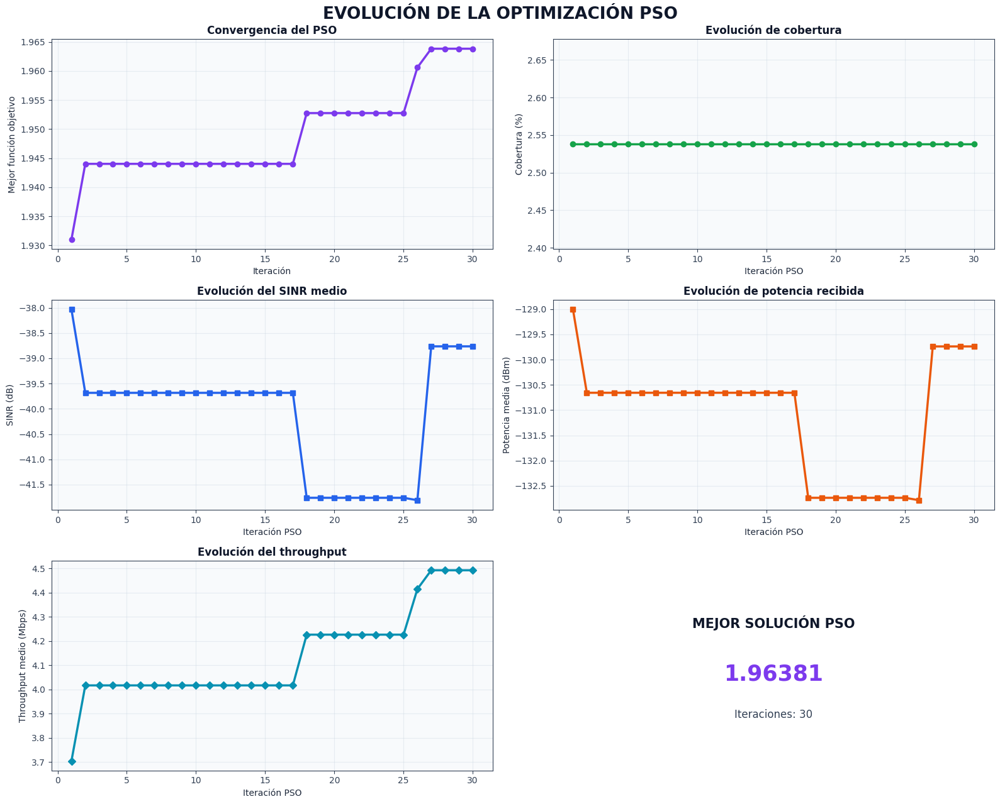

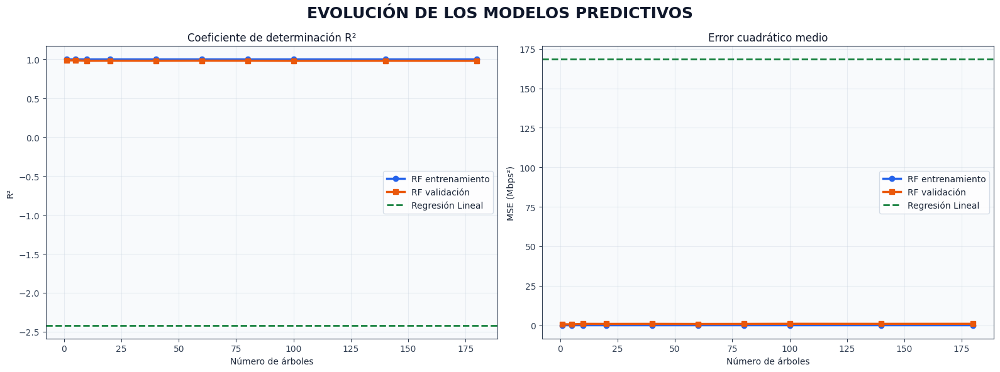

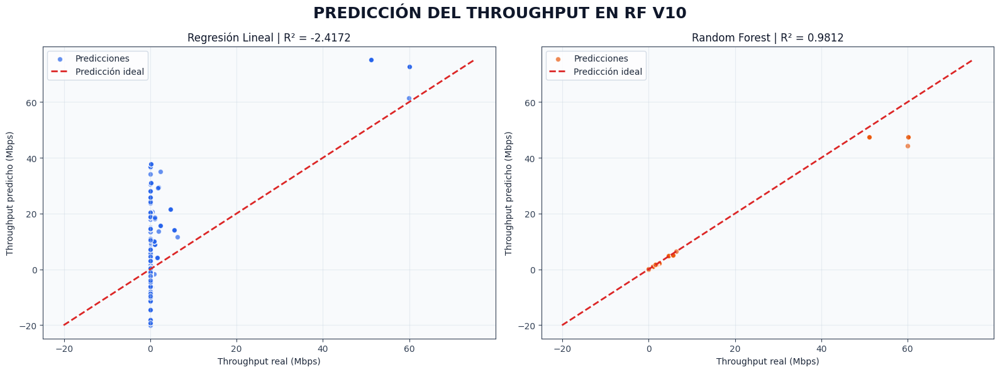

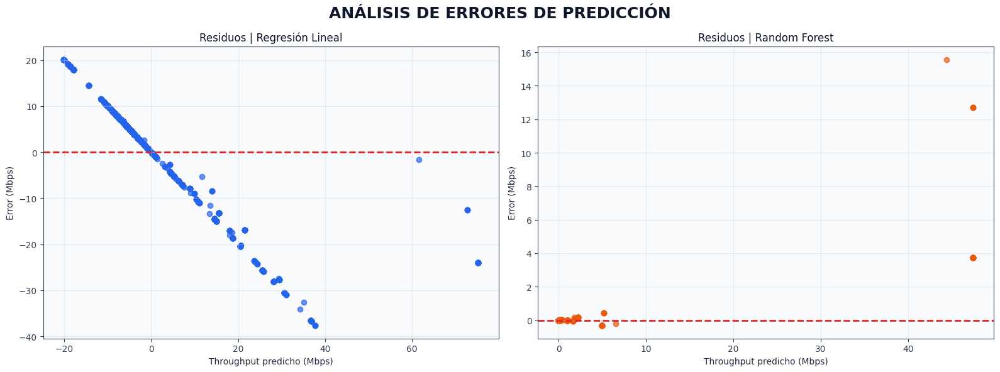

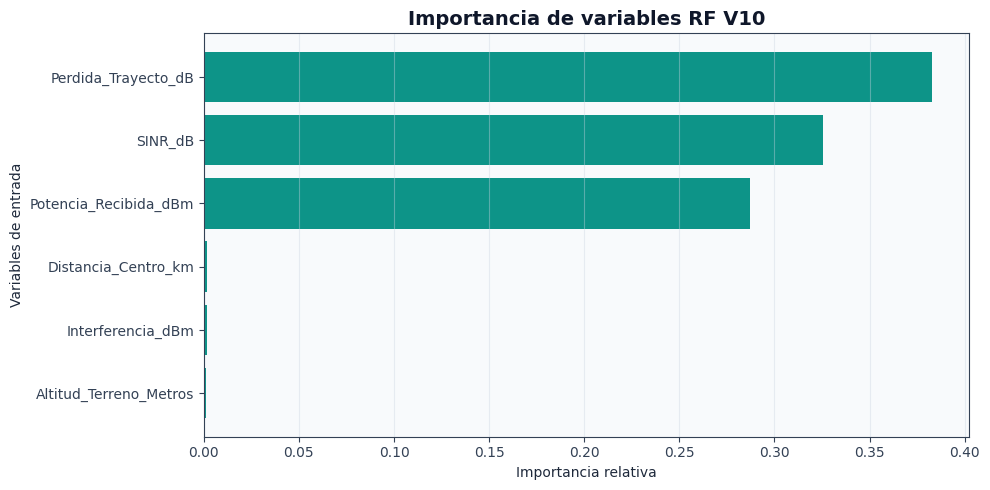

,Antena,Latitud,Longitud,Azimut (°),Distancia al centro (km)
0,1,7.098679,-73.118904,349.65,2.331
1,2,7.104831,-73.122563,359.46,1.609
2,3,7.102382,-73.132812,30.67,2.187
3,4,7.109039,-73.115575,325.43,1.386


,Modelo,R² entrenamiento,R² validación,MSE entrenamiento,MSE validación
0,Regresión Lineal,0.61608,-2.41717,308.83440,168.35552
1,Random Forest,0.99995,0.98116,0.04236,0.92811


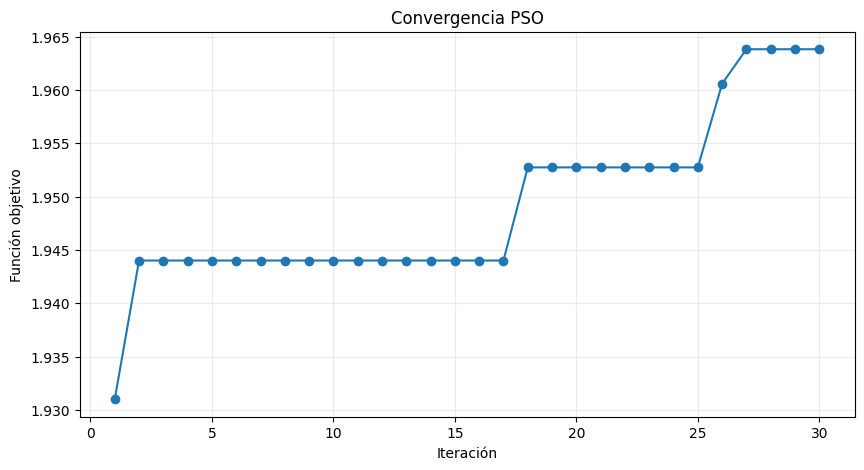

In [21]:
# @title RF V10 | PSO + Regresión Lineal + Random Forest
variable_name = "" # @param {"type":"string"}
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import r2_score, mean_squared_error
from IPython.display import display, HTML

# ============================================================
# 1. RECUPERAR LOS RESULTADOS REALES DEL PROYECTO
# ============================================================

# Resultado del algoritmo Particle Swarm Optimization
pso = result["result"]

# Dataset generado durante las iteraciones del PSO
df = result["raw"].copy()

# Verificar que el resultado contiene el objeto PSO esperado
if not hasattr(pso, "history") or not hasattr(pso, "snapshots"):
    raise ValueError(
        "No se encontró el historial o los snapshots del PSO."
    )

if df.empty:
    raise ValueError("El dataset RF generado está vacío.")

# ============================================================
# 2. VARIABLES DEL MODELO RF V10
# ============================================================

# Se conservan las seis variables originales de ml.py
features = [
    "Distancia_Centro_km",
    "Altitud_Terreno_Metros",
    "Perdida_Trayecto_dB",
    "Potencia_Recibida_dBm",
    "Interferencia_dBm",
    "SINR_dB"
]

target = "Throughput_Estimado_Mbps"

# Estas columnas permiten identificar las muestras generadas
# por cada punto geográfico durante las iteraciones del PSO.
group_columns = [
    "X_Local_km",
    "Y_Local_km"
]

required_columns = features + [target] + group_columns + ["Iteracion"]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Faltan columnas del dataset RF V10: {missing_columns}"
    )

data = (
    df[required_columns]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .copy()
)

if len(data) < 20:
    raise ValueError(
        f"Solo hay {len(data)} muestras válidas. "
        "Se necesitan al menos 20."
    )

X = data[features].to_numpy()
y = data[target].to_numpy()

# ============================================================
# 3. DIVISIÓN DE ENTRENAMIENTO Y VALIDACIÓN
# ============================================================

# En RF V10 se evalúa la mejor solución del PSO en cada iteración.
# Los mismos puntos de demanda aparecen repetidos entre iteraciones.
#
# Para evitar que muestras del mismo punto geográfico queden
# simultáneamente en entrenamiento y validación, agrupamos
# por coordenadas locales.

groups = pd.MultiIndex.from_frame(
    data[group_columns].round(6)
).factorize()[0]

if len(np.unique(groups)) < 5:
    raise ValueError(
        "No hay suficientes puntos geográficos diferentes "
        "para realizar la validación."
    )

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print("MUESTRAS RF V10")
print(f"Total: {len(data):,}")
print(f"Entrenamiento: {len(X_train):,}")
print(f"Validación: {len(X_test):,}")
print(f"Iteraciones PSO: {data['Iteracion'].nunique()}")

# ============================================================
# 4. ENTRENAMIENTO DE REGRESIÓN LINEAL
# ============================================================

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_train_pred = linear_model.predict(X_train)
linear_test_pred = linear_model.predict(X_test)

linear_train_r2 = r2_score(y_train, linear_train_pred)
linear_test_r2 = r2_score(y_test, linear_test_pred)

linear_train_mse = mean_squared_error(
    y_train, linear_train_pred
)

linear_test_mse = mean_squared_error(
    y_test, linear_test_pred
)

# ============================================================
# 5. ENTRENAMIENTO PROGRESIVO RANDOM FOREST
# ============================================================

n_trees = [1, 5, 10, 20, 40, 60, 80, 100, 140, 180]

rf_model = RandomForestRegressor(
    n_estimators=180,
    random_state=42,
    min_samples_leaf=2,
    warm_start=True,
    n_jobs=-1
)

rf_train_r2 = []
rf_test_r2 = []

rf_train_mse = []
rf_test_mse = []

for n in n_trees:

    rf_model.set_params(n_estimators=n)
    rf_model.fit(X_train, y_train)

    pred_train = rf_model.predict(X_train)
    pred_test = rf_model.predict(X_test)

    rf_train_r2.append(
        r2_score(y_train, pred_train)
    )

    rf_test_r2.append(
        r2_score(y_test, pred_test)
    )

    rf_train_mse.append(
        mean_squared_error(y_train, pred_train)
    )

    rf_test_mse.append(
        mean_squared_error(y_test, pred_test)
    )

# Predicciones del Random Forest definitivo
rf_train_pred = rf_model.predict(X_train)
rf_test_pred = rf_model.predict(X_test)

# ============================================================
# 6. RECUPERAR EL HISTORIAL Y MÉTRICAS DEL PSO
# ============================================================

pso_history = np.asarray(pso.history, dtype=float)

pso_snapshots = pd.DataFrame(pso.snapshots)

if pso_snapshots.empty:
    raise ValueError("El PSO no contiene snapshots.")

# Métricas registradas por el optimizador en cada iteración
pso_iterations = pso_snapshots["iteration"].to_numpy()

pso_coverage = pso_snapshots["coverage_percent"].to_numpy()
pso_sinr = pso_snapshots["mean_sinr_db"].to_numpy()
pso_power = pso_snapshots["mean_power_dbm"].to_numpy()
pso_throughput = pso_snapshots["mean_throughput_mbps"].to_numpy()

# ============================================================
# 7. CONFIGURACIÓN VISUAL
# ============================================================

plt.rcParams.update({
    "figure.facecolor": "#ffffff",
    "axes.facecolor": "#f8fafc",
    "axes.edgecolor": "#334155",
    "axes.labelcolor": "#1e293b",
    "xtick.color": "#334155",
    "ytick.color": "#334155",
    "text.color": "#0f172a",
    "axes.titlecolor": "#0f172a",
    "legend.facecolor": "#ffffff",
    "legend.edgecolor": "#cbd5e1",
    "grid.color": "#cbd5e1",
    "font.family": "DejaVu Sans"
})

display(HTML("""
<div style="
    background:#111827;
    color:#f9fafb;
    padding:20px;
    border-radius:12px;
    font-family:Arial,sans-serif;
">
    <h2 style="color:#38bdf8;margin:0 0 8px 0;">
        ANTENNA OPTIMIZER RF V10
    </h2>
    <p style="color:#e5e7eb;margin:0;">
        Optimización PSO · Regresión Lineal · Random Forest
    </p>
    <p style="color:#94a3b8;margin:8px 0 0 0;">
        Evaluación del sistema de simulación y aprendizaje automático
    </p>
</div>
"""))

# ============================================================
# 8. VISUALIZACIÓN DEL PROCESO PSO
# ============================================================

fig, axes = plt.subplots(3, 2, figsize=(16, 13))

fig.suptitle(
    "EVOLUCIÓN DE LA OPTIMIZACIÓN PSO",
    fontsize=19,
    fontweight="bold",
    color="#0f172a"
)

# ------------------------------------------------------------
# A. CONVERGENCIA DE LA FUNCIÓN OBJETIVO
# ------------------------------------------------------------

axes[0, 0].plot(
    np.arange(1, len(pso_history) + 1),
    pso_history,
    color="#7c3aed",
    marker="o",
    linewidth=2.5
)

axes[0, 0].set_title(
    "Convergencia del PSO",
    fontweight="bold"
)

axes[0, 0].set_xlabel("Iteración")
axes[0, 0].set_ylabel("Mejor función objetivo")
axes[0, 0].grid(alpha=0.4)

# ------------------------------------------------------------
# B. COBERTURA
# ------------------------------------------------------------

axes[0, 1].plot(
    pso_iterations,
    pso_coverage,
    color="#16a34a",
    marker="o",
    linewidth=2.5
)

axes[0, 1].set_title(
    "Evolución de cobertura",
    fontweight="bold"
)

axes[0, 1].set_xlabel("Iteración PSO")
axes[0, 1].set_ylabel("Cobertura (%)")
axes[0, 1].grid(alpha=0.4)

# ------------------------------------------------------------
# C. SINR
# ------------------------------------------------------------

axes[1, 0].plot(
    pso_iterations,
    pso_sinr,
    color="#2563eb",
    marker="s",
    linewidth=2.5
)

axes[1, 0].set_title(
    "Evolución del SINR medio",
    fontweight="bold"
)

axes[1, 0].set_xlabel("Iteración PSO")
axes[1, 0].set_ylabel("SINR (dB)")
axes[1, 0].grid(alpha=0.4)

# ------------------------------------------------------------
# D. POTENCIA RECIBIDA
# ------------------------------------------------------------

axes[1, 1].plot(
    pso_iterations,
    pso_power,
    color="#ea580c",
    marker="s",
    linewidth=2.5
)

axes[1, 1].set_title(
    "Evolución de potencia recibida",
    fontweight="bold"
)

axes[1, 1].set_xlabel("Iteración PSO")
axes[1, 1].set_ylabel("Potencia media (dBm)")
axes[1, 1].grid(alpha=0.4)

# ------------------------------------------------------------
# E. THROUGHPUT
# ------------------------------------------------------------

axes[2, 0].plot(
    pso_iterations,
    pso_throughput,
    color="#0891b2",
    marker="D",
    linewidth=2.5
)

axes[2, 0].set_title(
    "Evolución del throughput",
    fontweight="bold"
)

axes[2, 0].set_xlabel("Iteración PSO")
axes[2, 0].set_ylabel("Throughput medio (Mbps)")
axes[2, 0].grid(alpha=0.4)

# ------------------------------------------------------------
# F. PUNTUACIÓN FINAL
# ------------------------------------------------------------

axes[2, 1].axis("off")

axes[2, 1].text(
    0.5, 0.68,
    "MEJOR SOLUCIÓN PSO",
    ha="center",
    fontsize=15,
    fontweight="bold",
    color="#0f172a",
    transform=axes[2, 1].transAxes
)

axes[2, 1].text(
    0.5, 0.43,
    f"{pso.best_score:.5f}",
    ha="center",
    fontsize=25,
    fontweight="bold",
    color="#7c3aed",
    transform=axes[2, 1].transAxes
)

axes[2, 1].text(
    0.5, 0.25,
    f"Iteraciones: {len(pso_history)}",
    ha="center",
    fontsize=12,
    color="#334155",
    transform=axes[2, 1].transAxes
)

plt.tight_layout()
display(fig)
plt.close(fig)

# ============================================================
# 9. EVOLUCIÓN DEL APRENDIZAJE DE MACHINE LEARNING
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

fig.suptitle(
    "EVOLUCIÓN DE LOS MODELOS PREDICTIVOS",
    fontsize=18,
    fontweight="bold",
    color="#0f172a"
)

# R²
axes[0].plot(
    n_trees,
    rf_train_r2,
    color="#2563eb",
    marker="o",
    linewidth=2.5,
    label="RF entrenamiento"
)

axes[0].plot(
    n_trees,
    rf_test_r2,
    color="#ea580c",
    marker="s",
    linewidth=2.5,
    label="RF validación"
)

axes[0].axhline(
    linear_test_r2,
    color="#15803d",
    linestyle="--",
    linewidth=2,
    label="Regresión Lineal"
)

axes[0].set_title("Coeficiente de determinación R²")
axes[0].set_xlabel("Número de árboles")
axes[0].set_ylabel("R²")
axes[0].grid(alpha=0.4)
axes[0].legend(labelcolor="#1e293b")

# MSE
axes[1].plot(
    n_trees,
    rf_train_mse,
    color="#2563eb",
    marker="o",
    linewidth=2.5,
    label="RF entrenamiento"
)

axes[1].plot(
    n_trees,
    rf_test_mse,
    color="#ea580c",
    marker="s",
    linewidth=2.5,
    label="RF validación"
)

axes[1].axhline(
    linear_test_mse,
    color="#15803d",
    linestyle="--",
    linewidth=2,
    label="Regresión Lineal"
)

axes[1].set_title("Error cuadrático medio")
axes[1].set_xlabel("Número de árboles")
axes[1].set_ylabel("MSE (Mbps²)")
axes[1].grid(alpha=0.4)
axes[1].legend(labelcolor="#1e293b")

plt.tight_layout()
display(fig)
plt.close(fig)

# ============================================================
# 10. COMPARACIÓN DE PREDICCIONES
# ============================================================

global_min = min(
    y_test.min(),
    linear_test_pred.min(),
    rf_test_pred.min()
)

global_max = max(
    y_test.max(),
    linear_test_pred.max(),
    rf_test_pred.max()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

fig.suptitle(
    "PREDICCIÓN DEL THROUGHPUT EN RF V10",
    fontsize=18,
    fontweight="bold",
    color="#0f172a"
)

# REGRESIÓN LINEAL
axes[0].scatter(
    y_test,
    linear_test_pred,
    color="#2563eb",
    alpha=0.7,
    edgecolors="white",
    label="Predicciones"
)

axes[0].plot(
    [global_min, global_max],
    [global_min, global_max],
    color="#dc2626",
    linestyle="--",
    linewidth=2,
    label="Predicción ideal"
)

axes[0].set_title(
    f"Regresión Lineal | R² = {linear_test_r2:.4f}"
)

axes[0].set_xlabel("Throughput real (Mbps)")
axes[0].set_ylabel("Throughput predicho (Mbps)")
axes[0].grid(alpha=0.4)
axes[0].legend(labelcolor="#1e293b")

# RANDOM FOREST
axes[1].scatter(
    y_test,
    rf_test_pred,
    color="#ea580c",
    alpha=0.7,
    edgecolors="white",
    label="Predicciones"
)

axes[1].plot(
    [global_min, global_max],
    [global_min, global_max],
    color="#dc2626",
    linestyle="--",
    linewidth=2,
    label="Predicción ideal"
)

axes[1].set_title(
    f"Random Forest | R² = {rf_test_r2[-1]:.4f}"
)

axes[1].set_xlabel("Throughput real (Mbps)")
axes[1].set_ylabel("Throughput predicho (Mbps)")
axes[1].grid(alpha=0.4)
axes[1].legend(labelcolor="#1e293b")

plt.tight_layout()
display(fig)
plt.close(fig)

# ============================================================
# 11. ANÁLISIS DE RESIDUOS
# ============================================================

linear_residuals = y_test - linear_test_pred
rf_residuals = y_test - rf_test_pred

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

fig.suptitle(
    "ANÁLISIS DE ERRORES DE PREDICCIÓN",
    fontsize=18,
    fontweight="bold",
    color="#0f172a"
)

axes[0].scatter(
    linear_test_pred,
    linear_residuals,
    color="#2563eb",
    alpha=0.7
)

axes[0].axhline(
    0,
    color="#dc2626",
    linestyle="--",
    linewidth=2
)

axes[0].set_title("Residuos | Regresión Lineal")
axes[0].set_xlabel("Throughput predicho (Mbps)")
axes[0].set_ylabel("Error (Mbps)")
axes[0].grid(alpha=0.4)

axes[1].scatter(
    rf_test_pred,
    rf_residuals,
    color="#ea580c",
    alpha=0.7
)

axes[1].axhline(
    0,
    color="#dc2626",
    linestyle="--",
    linewidth=2
)

axes[1].set_title("Residuos | Random Forest")
axes[1].set_xlabel("Throughput predicho (Mbps)")
axes[1].set_ylabel("Error (Mbps)")
axes[1].grid(alpha=0.4)

plt.tight_layout()
display(fig)
plt.close(fig)

# ============================================================
# 12. IMPORTANCIA DE VARIABLES RANDOM FOREST
# ============================================================

importances = pd.Series(
    rf_model.feature_importances_,
    index=features
).sort_values()

fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    importances.index,
    importances.values,
    color="#0d9488"
)

ax.set_title(
    "Importancia de variables RF V10",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Importancia relativa")
ax.set_ylabel("Variables de entrada")
ax.grid(axis="x", alpha=0.4)

plt.tight_layout()
display(fig)
plt.close(fig)

# ============================================================
# 13. POSICIONES OPTIMIZADAS POR EL PSO
# ============================================================

antennas_pso = pd.DataFrame({
    "Antena": np.arange(1, len(pso.coordinates) + 1),
    "Latitud": [c[0] for c in pso.coordinates],
    "Longitud": [c[1] for c in pso.coordinates],
    "Azimut (°)": pso.azimuths_deg,
    "Distancia al centro (km)": pso.distances_km
})

display(HTML("""
<h3 style="color:#0f172a;">
    Configuración final de antenas optimizada por PSO
</h3>
"""))

display(
    antennas_pso.style
    .format({
        "Latitud": "{:.6f}",
        "Longitud": "{:.6f}",
        "Azimut (°)": "{:.2f}",
        "Distancia al centro (km)": "{:.3f}"
    })
    .set_properties(**{
        "color": "#0f172a",
        "background-color": "#f8fafc",
        "text-align": "center"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#1e293b"),
                ("color", "#ffffff")
            ]
        }
    ])
)

# ============================================================
# 14. TABLA COMPARATIVA DE MODELOS
# ============================================================

comparison = pd.DataFrame({
    "Modelo": [
        "Regresión Lineal",
        "Random Forest"
    ],

    "R² entrenamiento": [
        linear_train_r2,
        rf_train_r2[-1]
    ],

    "R² validación": [
        linear_test_r2,
        rf_test_r2[-1]
    ],

    "MSE entrenamiento": [
        linear_train_mse,
        rf_train_mse[-1]
    ],

    "MSE validación": [
        linear_test_mse,
        rf_test_mse[-1]
    ]
})

display(HTML("""
<h3 style="color:#0f172a;">
    Comparación de rendimiento de Machine Learning
</h3>
"""))

display(
    comparison.style
    .format({
        "R² entrenamiento": "{:.5f}",
        "R² validación": "{:.5f}",
        "MSE entrenamiento": "{:.5f}",
        "MSE validación": "{:.5f}"
    })
    .set_properties(**{
        "color": "#0f172a",
        "background-color": "#f8fafc",
        "text-align": "center"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#1e293b"),
                ("color", "#ffffff"),
                ("font-weight", "bold")
            ]
        }
    ])
)

# ============================================================
# 15. RESUMEN GENERAL DEL PROYECTO
# ============================================================

best_model = (
    "Random Forest"
    if rf_test_r2[-1] > linear_test_r2
    else "Regresión Lineal"
)

display(HTML(f"""
<div style="
    background:#e0f2fe;
    color:#0c4a6e;
    padding:20px;
    border-radius:12px;
    font-family:Arial,sans-serif;
    border:1px solid #7dd3fc;
">

    <h3 style="color:#075985;margin-top:0;">
        Resumen general | ANTENNA OPTIMIZER RF V10
    </h3>

    <h4 style="color:#0369a1;">Optimización PSO</h4>

    <p><b>Iteraciones:</b> {len(pso_history)}</p>
    <p><b>Mejor puntuación PSO:</b> {pso.best_score:.5f}</p>

    <p><b>Cobertura final:</b>
    {pso_coverage[-1]:.3f}%</p>

    <p><b>SINR medio final:</b>
    {pso_sinr[-1]:.3f} dB</p>

    <p><b>Throughput medio final:</b>
    {pso_throughput[-1]:.3f} Mbps</p>

    <hr style="border:1px solid #7dd3fc;">

    <h4 style="color:#0369a1;">Machine Learning</h4>

    <p><b>Muestras:</b> {len(data):,}</p>

    <p><b>R² Regresión Lineal:</b>
    {linear_test_r2:.5f}</p>

    <p><b>R² Random Forest:</b>
    {rf_test_r2[-1]:.5f}</p>

    <p><b>MSE Regresión Lineal:</b>
    {linear_test_mse:.5f} Mbps²</p>

    <p><b>MSE Random Forest:</b>
    {rf_test_mse[-1]:.5f} Mbps²</p>

    <hr style="border:1px solid #7dd3fc;">

    <h4 style="color:#0369a1;">
        Mejor modelo predictivo según R² de validación
    </h4>

    <h2 style="color:#0369a1;margin-bottom:0;">
        {best_model}
    </h2>

</div>
"""))

In [25]:
# @title RF V10 | Preparación de datos para PCA y t-SNE

%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from IPython.display import display, HTML

# ============================================================
# 1. RECUPERAR RESULTADOS DEL PROYECTO
# ============================================================

if not isinstance(result, dict):
    raise TypeError(
        "La variable result no contiene el diccionario "
        "de resultados de RF V10."
    )

rf10_pso = result.get("result")
rf10_raw = result.get("raw")

if rf10_raw is None or rf10_pso is None:
    raise ValueError(
        "No se encontraron los resultados del PSO o el dataset RF."
    )

if not hasattr(rf10_pso, "history"):
    raise ValueError("No se encontró el historial del PSO.")

# ============================================================
# 2. VARIABLES ORIGINALES DE RF V10
# ============================================================

rf10_features = [
    "Distancia_Centro_km",
    "Altitud_Terreno_Metros",
    "Perdida_Trayecto_dB",
    "Potencia_Recibida_dBm",
    "Interferencia_dBm",
    "SINR_dB"
]

rf10_target = "Throughput_Estimado_Mbps"

rf10_required = (
    rf10_features +
    [rf10_target, "Iteracion"]
)

rf10_missing = [
    col for col in rf10_required
    if col not in rf10_raw.columns
]

if rf10_missing:
    raise ValueError(
        f"Faltan columnas del dataset: {rf10_missing}"
    )

# ============================================================
# 3. LIMPIEZA Y PREPARACIÓN
# ============================================================

rf10_data = rf10_raw[rf10_required].copy()

rf10_data = rf10_data.replace(
    [np.inf, -np.inf],
    np.nan
)

rf10_data["Iteracion"] = pd.to_numeric(
    rf10_data["Iteracion"],
    errors="coerce"
)

rf10_data = rf10_data.dropna().reset_index(drop=True)

rf10_data["Iteracion"] = (
    rf10_data["Iteracion"].astype(int)
)

if len(rf10_data) < 3:
    raise ValueError(
        "No existen suficientes muestras para PCA y t-SNE."
    )

# Separar variables de entrada y variable objetivo
rf10_X = rf10_data[rf10_features].to_numpy()

rf10_y = rf10_data[rf10_target].to_numpy()

rf10_iterations = rf10_data["Iteracion"].to_numpy()

# ============================================================
# 4. NORMALIZACIÓN DE VARIABLES
# ============================================================

# Estandarización necesaria porque las variables RF
# manejan unidades y escalas diferentes.

rf10_scaler = StandardScaler()

rf10_X_scaled = rf10_scaler.fit_transform(rf10_X)

# ============================================================
# 5. RECUPERAR HISTORIAL PSO
# ============================================================

rf10_pso_history = np.asarray(
    rf10_pso.history,
    dtype=float
)

if len(rf10_pso_history) == 0:
    raise ValueError("El historial del PSO está vacío.")

# ============================================================
# 6. CONFIGURACIÓN VISUAL
# ============================================================

plt.rcParams.update({
    "figure.facecolor": "#ffffff",
    "axes.facecolor": "#f8fafc",
    "axes.edgecolor": "#334155",
    "axes.labelcolor": "#1e293b",
    "xtick.color": "#334155",
    "ytick.color": "#334155",
    "text.color": "#0f172a",
    "axes.titlecolor": "#0f172a",
    "legend.facecolor": "#ffffff",
    "legend.edgecolor": "#cbd5e1",
    "grid.color": "#cbd5e1",
    "font.family": "DejaVu Sans"
})

# ============================================================
# 7. ENCABEZADO DEL ANÁLISIS
# ============================================================

display(HTML("""
<div style="
    background:#111827;
    color:#f9fafb;
    padding:20px;
    border-radius:12px;
    font-family:Arial;
">
    <h2 style="color:#38bdf8;margin:0;">
        ANTENNA OPTIMIZER RF V10
    </h2>
    <p style="color:#e5e7eb;margin:8px 0 0;">
        Análisis de dimensionalidad | PCA y t-SNE
    </p>
    <p style="color:#94a3b8;margin:5px 0 0;">
        Datos RF generados durante la optimización PSO
    </p>
</div>
"""))

display(HTML(f"""
<div style="
    background:#e0f2fe;
    color:#0c4a6e;
    padding:16px;
    border-radius:10px;
    font-family:Arial;
    margin-top:12px;
">
    <h3 style="color:#075985;margin-top:0;">
        Datos preparados
    </h3>
    <b>Muestras:</b> {len(rf10_data):,}<br>
    <b>Variables RF:</b> {len(rf10_features)}<br>
    <b>Iteraciones PSO representadas:</b>
    {rf10_data["Iteracion"].nunique()}<br>
    <b>Mejor puntuación PSO:</b>
    {rf10_pso.best_score:.5f}
</div>
"""))

print("Preparación finalizada.")
print("Datos listos para PCA y t-SNE.")

Preparación finalizada.
Datos listos para PCA y t-SNE.


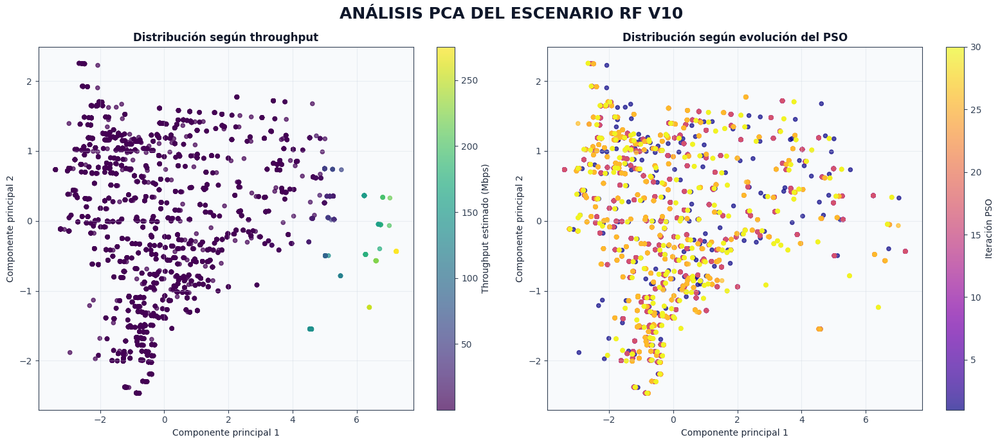

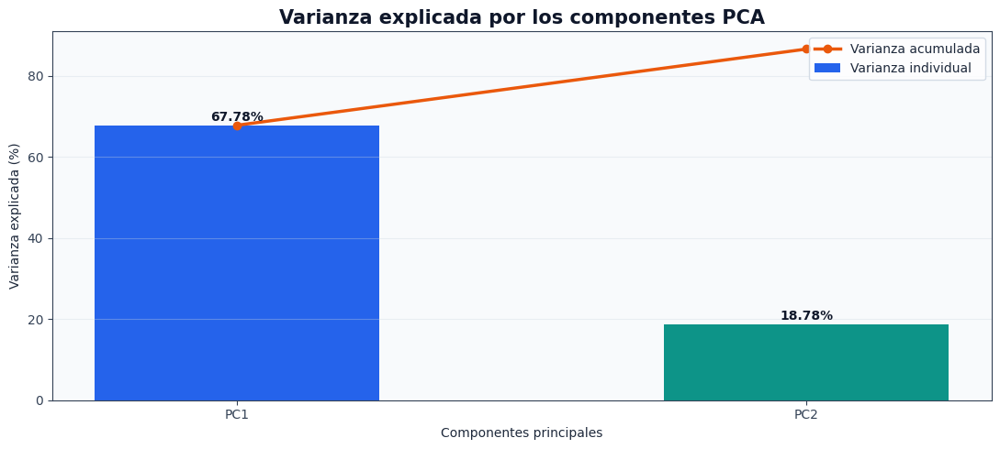

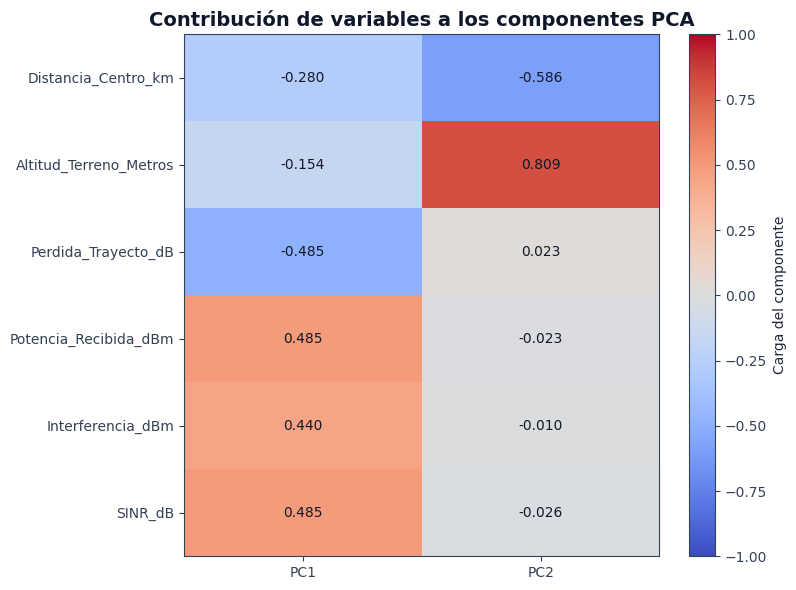

,PC1,PC2
Distancia_Centro_km,-0.27964,-0.58622
Altitud_Terreno_Metros,-0.15433,0.80904
Perdida_Trayecto_dB,-0.48450,0.02270
Potencia_Recibida_dBm,0.48450,-0.02270
Interferencia_dBm,0.43968,-0.01032
SINR_dB,0.48495,-0.02585


In [23]:
# @title RF V10 | PCA - Análisis de Componentes Principales

# ============================================================
# 1. APLICAR PCA
# ============================================================

rf10_pca = PCA(
    n_components=2,
    random_state=42
)

rf10_pca_scores = rf10_pca.fit_transform(
    rf10_X_scaled
)

rf10_pca_df = pd.DataFrame({
    "PC1": rf10_pca_scores[:, 0],
    "PC2": rf10_pca_scores[:, 1],
    "Throughput": rf10_y,
    "Iteracion": rf10_iterations
})

# ============================================================
# 2. VARIANZA EXPLICADA
# ============================================================

rf10_pca_variance = (
    rf10_pca.explained_variance_ratio_ * 100
)

rf10_pca_cumulative = np.cumsum(
    rf10_pca_variance
)

# ============================================================
# 3. ENCABEZADO
# ============================================================

display(HTML("""
<div style="
    background:#172554;
    color:white;
    padding:18px;
    border-radius:12px;
    font-family:Arial;
">
    <h2 style="color:#93c5fd;margin:0;">
        PCA | Reducción de dimensionalidad
    </h2>
    <p style="color:#e2e8f0;margin:8px 0 0;">
        Proyección de seis variables RF en dos componentes principales
    </p>
</div>
"""))

# ============================================================
# 4. GRÁFICAS DE COMPONENTES PRINCIPALES
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

fig.suptitle(
    "ANÁLISIS PCA DEL ESCENARIO RF V10",
    fontsize=18,
    fontweight="bold",
    color="#0f172a"
)

# ------------------------------------------------------------
# A. PCA COLOREADO POR THROUGHPUT
# ------------------------------------------------------------

scatter1 = axes[0].scatter(
    rf10_pca_df["PC1"],
    rf10_pca_df["PC2"],
    c=rf10_pca_df["Throughput"],
    cmap="viridis",
    s=20,
    alpha=0.7
)

fig.colorbar(
    scatter1,
    ax=axes[0],
    label="Throughput estimado (Mbps)"
)

axes[0].set_title(
    "Distribución según throughput",
    fontweight="bold"
)

axes[0].set_xlabel("Componente principal 1")
axes[0].set_ylabel("Componente principal 2")
axes[0].grid(alpha=0.35)

# ------------------------------------------------------------
# B. PCA COLOREADO POR ITERACIÓN PSO
# ------------------------------------------------------------

scatter2 = axes[1].scatter(
    rf10_pca_df["PC1"],
    rf10_pca_df["PC2"],
    c=rf10_pca_df["Iteracion"],
    cmap="plasma",
    s=20,
    alpha=0.7
)

fig.colorbar(
    scatter2,
    ax=axes[1],
    label="Iteración PSO"
)

axes[1].set_title(
    "Distribución según evolución del PSO",
    fontweight="bold"
)

axes[1].set_xlabel("Componente principal 1")
axes[1].set_ylabel("Componente principal 2")
axes[1].grid(alpha=0.35)

plt.tight_layout()
display(fig)
plt.close(fig)

# ============================================================
# 5. VARIANZA EXPLICADA
# ============================================================

fig, ax = plt.subplots(figsize=(11, 5))

components = ["PC1", "PC2"]

ax.bar(
    components,
    rf10_pca_variance,
    color=["#2563eb", "#0d9488"],
    width=0.5,
    label="Varianza individual"
)

ax.plot(
    components,
    rf10_pca_cumulative,
    color="#ea580c",
    marker="o",
    linewidth=2.5,
    label="Varianza acumulada"
)

for i, value in enumerate(rf10_pca_variance):
    ax.text(
        i,
        value + 1,
        f"{value:.2f}%",
        ha="center",
        fontweight="bold",
        color="#0f172a"
    )

ax.set_title(
    "Varianza explicada por los componentes PCA",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Componentes principales")
ax.set_ylabel("Varianza explicada (%)")
ax.grid(axis="y", alpha=0.35)
ax.legend(labelcolor="#1e293b")

plt.tight_layout()
display(fig)
plt.close(fig)

# ============================================================
# 6. CARGAS DE LAS VARIABLES
# ============================================================

rf10_pca_loadings = pd.DataFrame(
    rf10_pca.components_.T,
    index=rf10_features,
    columns=["PC1", "PC2"]
)

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(
    rf10_pca_loadings.values,
    cmap="coolwarm",
    aspect="auto",
    vmin=-1,
    vmax=1
)

ax.set_xticks([0, 1])
ax.set_xticklabels(["PC1", "PC2"])

ax.set_yticks(
    np.arange(len(rf10_features))
)

ax.set_yticklabels(rf10_features)

ax.set_title(
    "Contribución de variables a los componentes PCA",
    fontsize=14,
    fontweight="bold"
)

for i in range(len(rf10_features)):
    for j in range(2):
        ax.text(
            j,
            i,
            f"{rf10_pca_loadings.iloc[i, j]:.3f}",
            ha="center",
            va="center",
            color="#111827"
        )

fig.colorbar(
    im,
    ax=ax,
    label="Carga del componente"
)

plt.tight_layout()
display(fig)
plt.close(fig)

# ============================================================
# 7. TABLA DE CARGAS PCA
# ============================================================

display(HTML("""
<h3 style="color:#0f172a;">
    Cargas de las variables en PCA
</h3>
"""))

display(
    rf10_pca_loadings.style
    .format("{:.5f}")
    .set_properties(**{
        "color": "#0f172a",
        "background-color": "#f8fafc",
        "text-align": "center"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#1e293b"),
                ("color", "#ffffff")
            ]
        }
    ])
)

# ============================================================
# 8. RESULTADOS PCA
# ============================================================

display(HTML(f"""
<div style="
    background:#e0f2fe;
    color:#0c4a6e;
    padding:18px;
    border-radius:10px;
    font-family:Arial;
    border:1px solid #7dd3fc;
">
    <h3 style="color:#075985;margin-top:0;">
        Resultados PCA | RF V10
    </h3>

    <p><b>Muestras analizadas:</b> {len(rf10_pca_df):,}</p>

    <p><b>Variables originales:</b> {len(rf10_features)}</p>

    <p><b>Componentes generados:</b> 2</p>

    <p><b>Varianza explicada PC1:</b>
    {rf10_pca_variance[0]:.3f}%</p>

    <p><b>Varianza explicada PC2:</b>
    {rf10_pca_variance[1]:.3f}%</p>

    <p><b>Varianza acumulada:</b>
    {rf10_pca_cumulative[-1]:.3f}%</p>
</div>
"""))

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 3000 samples in 0.006s...
[t-SNE] Computed neighbors for 3000 samples in 0.109s...
[t-SNE] Computed conditional probabilities for sample 1000 / 3000
[t-SNE] Computed conditional probabilities for sample 2000 / 3000
[t-SNE] Computed conditional probabilities for sample 3000 / 3000
[t-SNE] Mean sigma: 0.224634
[t-SNE] KL divergence after 250 iterations with early exaggeration: 50.520054
[t-SNE] KL divergence after 1000 iterations: -0.670883


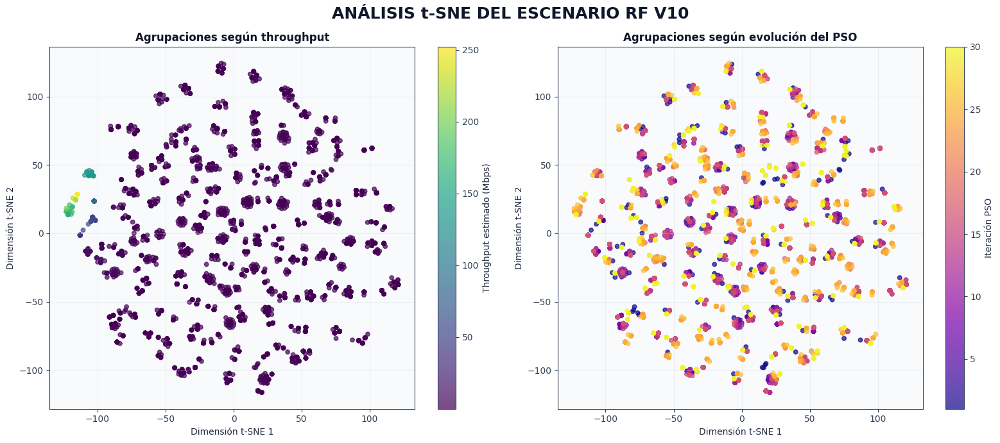

Análisis PCA y t-SNE finalizado.


In [24]:
# @title RF V10 | t-SNE - Visualización de agrupaciones RF

# ============================================================
# 1. PREPARAR MUESTRAS PARA t-SNE
# ============================================================

MAX_TSNE_SAMPLES = 3000

# Selección equilibrada por iteración del PSO
# para evitar que una iteración domine la visualización.

rf10_groups = list(
    rf10_data.groupby("Iteracion", sort=True)
)

rf10_samples_per_iteration = max(
    1,
    MAX_TSNE_SAMPLES // len(rf10_groups)
)

rf10_tsne_parts = []

for iteration, group in rf10_groups:

    n = min(
        len(group),
        rf10_samples_per_iteration
    )

    rf10_tsne_parts.append(
        group.sample(
            n=n,
            random_state=42
        )
    )

rf10_tsne_data = pd.concat(
    rf10_tsne_parts,
    ignore_index=True
)

# Si todavía supera el límite, reducirlo.
if len(rf10_tsne_data) > MAX_TSNE_SAMPLES:

    rf10_tsne_data = rf10_tsne_data.sample(
        n=MAX_TSNE_SAMPLES,
        random_state=42
    ).reset_index(drop=True)

# ============================================================
# 2. NORMALIZAR MUESTRA
# ============================================================

rf10_tsne_X = rf10_scaler.transform(
    rf10_tsne_data[rf10_features].to_numpy()
)

rf10_tsne_n = len(rf10_tsne_X)

if rf10_tsne_n < 3:
    raise ValueError(
        "Se necesitan al menos tres muestras para ejecutar t-SNE."
    )

# Perplexity debe ser menor que el número de muestras.
rf10_tsne_perplexity = min(
    30.0,
    max(2.0, (rf10_tsne_n - 1) / 3.0)
)

# ============================================================
# 3. CONFIGURAR Y ENTRENAR t-SNE
# ============================================================

import inspect

rf10_tsne_params = {
    "n_components": 2,
    "perplexity": rf10_tsne_perplexity,
    "learning_rate": "auto",
    "init": "pca",
    "random_state": 42,
    "method": "barnes_hut",
    "verbose": 1
}

# Compatibilidad con distintas versiones de Scikit-learn.
if "max_iter" in inspect.signature(TSNE).parameters:
    rf10_tsne_params["max_iter"] = 1000
else:
    rf10_tsne_params["n_iter"] = 1000

rf10_tsne_model = TSNE(
    **rf10_tsne_params
)

rf10_tsne_scores = rf10_tsne_model.fit_transform(
    rf10_tsne_X
)

# ============================================================
# 4. ORGANIZAR RESULTADOS
# ============================================================

rf10_tsne_df = pd.DataFrame({
    "TSNE1": rf10_tsne_scores[:, 0],
    "TSNE2": rf10_tsne_scores[:, 1],
    "Throughput": rf10_tsne_data[
        rf10_target
    ].to_numpy(),
    "Iteracion": rf10_tsne_data[
        "Iteracion"
    ].to_numpy()
})

# ============================================================
# 5. ENCABEZADO
# ============================================================

display(HTML("""
<div style="
    background:#172554;
    color:#ffffff;
    padding:18px;
    border-radius:12px;
    font-family:Arial;
">
    <h2 style="color:#93c5fd;margin:0;">
        t-SNE | Distribución de condiciones RF
    </h2>

    <p style="color:#e2e8f0;margin:8px 0 0;">
        Visualización de patrones y agrupaciones
        del escenario optimizado mediante PSO
    </p>
</div>
"""))

# ============================================================
# 6. t-SNE COLOREADO POR THROUGHPUT
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

fig.suptitle(
    "ANÁLISIS t-SNE DEL ESCENARIO RF V10",
    fontsize=18,
    fontweight="bold",
    color="#0f172a"
)

scatter1 = axes[0].scatter(
    rf10_tsne_df["TSNE1"],
    rf10_tsne_df["TSNE2"],
    c=rf10_tsne_df["Throughput"],
    cmap="viridis",
    s=22,
    alpha=0.7
)

fig.colorbar(
    scatter1,
    ax=axes[0],
    label="Throughput estimado (Mbps)"
)

axes[0].set_title(
    "Agrupaciones según throughput",
    fontweight="bold"
)

axes[0].set_xlabel("Dimensión t-SNE 1")
axes[0].set_ylabel("Dimensión t-SNE 2")
axes[0].grid(alpha=0.3)

# ============================================================
# 7. t-SNE COLOREADO POR ITERACIÓN PSO
# ============================================================

scatter2 = axes[1].scatter(
    rf10_tsne_df["TSNE1"],
    rf10_tsne_df["TSNE2"],
    c=rf10_tsne_df["Iteracion"],
    cmap="plasma",
    s=22,
    alpha=0.7
)

fig.colorbar(
    scatter2,
    ax=axes[1],
    label="Iteración PSO"
)

axes[1].set_title(
    "Agrupaciones según evolución del PSO",
    fontweight="bold"
)

axes[1].set_xlabel("Dimensión t-SNE 1")
axes[1].set_ylabel("Dimensión t-SNE 2")
axes[1].grid(alpha=0.3)

plt.tight_layout()
display(fig)
plt.close(fig)

# ============================================================
# 8. RESULTADOS t-SNE
# ============================================================

display(HTML(f"""
<div style="
    background:#e0f2fe;
    color:#0c4a6e;
    padding:18px;
    border-radius:10px;
    font-family:Arial;
    border:1px solid #7dd3fc;
">
    <h3 style="color:#075985;margin-top:0;">
        Resultados t-SNE | RF V10
    </h3>

    <p><b>Muestras originales:</b>
    {len(rf10_data):,}</p>

    <p><b>Muestras procesadas:</b>
    {rf10_tsne_n:,}</p>

    <p><b>Variables originales:</b>
    {len(rf10_features)}</p>

    <p><b>Dimensiones resultantes:</b> 2</p>

    <p><b>Perplexity:</b>
    {rf10_tsne_perplexity:.2f}</p>

    <p><b>Error final de t-SNE:</b>
    {rf10_tsne_model.kl_divergence_:.5f}</p>
</div>
"""))

print("Análisis PCA y t-SNE finalizado.")

## Archivos principales
- `mapa_rf_interactivo_offline.html`
- `vista_ciudad_rf_3d.html`
- `reporte_antenas_limpio.csv`
- `base_datos_rf.sqlite`
